# Module project: what really helps when data is scarce?

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-6-small-data-regularization.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-2-deep-networks/files/project-6-small-data-regularization.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/small-data-regularization` folder in the course files, to check your work.
- **Data**: Fashion-MNIST (Zalando Research). Source: [https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion](https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion) · about: [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist) · licence: MIT. `data.py` downloads it the first time you run it and keeps it in `data/`: `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`, `train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, 29.4 MB.

In [ ]:
%pip install -q torch matplotlib

Chapter 9 lists the ways to make a network generalize: weight decay, early stopping, data augmentation, dropout, model
averaging, and choosing an architecture with the right inductive bias. Tutorials usually show each one helping on a
problem picked to make it look good. In this project you do what a professional does instead: an **ablation study**,
switching each method on alone, under identical conditions, measuring the noise, and reporting what you find even when
it's not what you expected.

The setting is realistic: you only have 1,000 labelled images. The notebook attached above builds and runs the whole
project; the reference code is in the course files under `projects/small-data-regularization`.





## What you'll build

```mermaid
flowchart LR
    A[1,000 Fashion-MNIST<br/>training images] --> B[regularize.py<br/>one train function,<br/>every regularizer a switch]
    B --> C[study.py<br/>ablation + seeds +<br/>ensemble + CNN]
    B --> D[learning_curve.py<br/>what would more<br/>data give?]
    C --> E[test set, once]
```

## Set up the project

```bash
mkdir small-data-regularization && cd small-data-regularization
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

Copy `data.py` from your clothes classifier (part 1).

```text
small-data-regularization/
    .gitignore
    README.md
    best.pt
    data.py
    learning_curve.py
    regularize.py
    requirements.txt
    study.py
```

In [ ]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


In [ ]:
%%writefile data.py
"""Fashion-MNIST: 70,000 grey 28x28 photos of clothes in 10 classes (Zalando Research)."""
from pathlib import Path
from urllib.request import urlopen
import gzip
import torch

URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]


def _read(name, offset):
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        path.write_bytes(urlopen(URL + name).read())
    raw = gzip.decompress(path.read_bytes())
    return torch.frombuffer(bytearray(raw[offset:]), dtype=torch.uint8)


def load(split):
    """split: 'train' (60,000 images) or 't10k' (10,000). Returns images as (N, 784) floats in [0, 1] and labels."""
    x = _read(f"{split}-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
    t = _read(f"{split}-labels-idx1-ubyte.gz", 8).long()
    return x, t


def load_splits():
    x, t = load("train")
    g = torch.Generator().manual_seed(0)
    order = torch.randperm(len(x), generator=g)
    val, train = order[:10000], order[10000:]
    return (x[train], t[train]), (x[val], t[val]), load("t10k")


if __name__ == "__main__":
    (xtr, ttr), (xva, tva), (xte, tte) = load_splits()
    print(f"train {len(xtr)}, validation {len(xva)}, test {len(xte)} images of {xtr.shape[1]} pixels")
    print("images per class in training:", torch.bincount(ttr).tolist())

Writing data.py


## Step 1: one training function, many switches

`train(cfg)` trains a network with two hidden layers of 512 units for 100 epochs on the 1,000 images, and each key of
`cfg` switches on one method from the chapter:

- `weight_decay`: the L2 penalty of section 9.2 (AdamW applies it directly to the weights).
- `dropout`: randomly zeroes half the hidden units at each training step (section 9.6.1).
- `early_stopping`: keeps the weights from the epoch with the best validation accuracy (section 9.3.1).
- `augment`: shifts each training image by up to 2 pixels, teaching invariance to small translations (section 9.1.3).
- `conv`: replaces the network with a small convolutional network, a different inductive bias (section 9.1; you'll
  study convolutions properly in part 3).

In [ ]:
%%writefile regularize.py
"""Training with each regularizer of chapter 9, switched on by a config dict."""
import copy
import torch
import torch.nn.functional as F
from torch import nn
from data import load_splits

(XTR, TTR), (XVA, TVA), (XTE, TTE) = load_splits()
g = torch.Generator().manual_seed(0)
SMALL = torch.randperm(len(XTR), generator=g)[:1000]          # only 1,000 training images
X1K, T1K = XTR[SMALL], TTR[SMALL]
XVA, TVA = XVA[:2000], TVA[:2000]                             # a validation set for choices and early stopping


def network(dropout=0.0, conv=False):
    if conv:                                                  # a small convolutional network: a preview of part 3
        return nn.Sequential(nn.Unflatten(1, (1, 28, 28)),
                             nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Flatten(), nn.Linear(32 * 7 * 7, 10))
    return nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Dropout(dropout),
                         nn.Linear(512, 512), nn.ReLU(), nn.Dropout(dropout),
                         nn.Linear(512, 10))


def augment(x):
    """Shift each image by up to 2 pixels in each direction (section 9.1.3: data augmentation)."""
    imgs = x.reshape(-1, 1, 28, 28)
    padded = F.pad(imgs, (2, 2, 2, 2))
    out = torch.empty_like(imgs)
    dx, dy = torch.randint(0, 5, (2, len(x)))
    for i in range(len(x)):
        out[i] = padded[i, :, dy[i]:dy[i] + 28, dx[i]:dx[i] + 28]
    return out.reshape(-1, 784)


def accuracy(model, x, t):
    model.eval()
    with torch.no_grad():
        return (model(x).argmax(1) == t).float().mean().item()


def train(cfg, seed=0, epochs=100):
    """cfg keys: weight_decay, dropout, augment (bool), early_stopping (bool), conv (bool)."""
    torch.manual_seed(seed)
    model = network(cfg.get("dropout", 0.0), cfg.get("conv", False))
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=cfg.get("weight_decay", 0.0))
    best, best_state, curve = -1.0, None, []
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X1K))
        for start in range(0, len(X1K), 100):
            idx = order[start:start + 100]
            x = augment(X1K[idx]) if cfg.get("augment") else X1K[idx]
            loss = F.cross_entropy(model(x), T1K[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        val = accuracy(model, XVA, TVA)
        curve.append((accuracy(model, X1K, T1K), val))
        if cfg.get("early_stopping") and val > best:              # section 9.3.1
            best, best_state = val, copy.deepcopy(model.state_dict())
    if cfg.get("early_stopping"):
        model.load_state_dict(best_state)
    return model, curve

Writing regularize.py


## Step 2: the ablation study

In [ ]:
%%writefile study.py
"""Ablation study on 1,000 training images: each regularizer alone, all together, model averaging,
and a different architecture. Then the test set, once."""
import torch
from regularize import train, accuracy, X1K, T1K, XVA, TVA, XTE, TTE

STUDY = {
    "no regularization": {},
    "weight decay 0.1": {"weight_decay": 0.1},
    "dropout 0.5": {"dropout": 0.5},
    "early stopping": {"early_stopping": True},
    "data augmentation (shifts)": {"augment": True},
    "all of the above": {"weight_decay": 0.1, "dropout": 0.5, "early_stopping": True, "augment": True},
    "small CNN, no regularization": {"conv": True},
}
models = {}
print(f"{'setup':30s} {'train acc':>9s} {'val acc':>8s}")
for name, cfg in STUDY.items():
    model, _ = train(cfg)
    models[name] = model
    print(f"{name:30s} {accuracy(model, X1K, T1K):9.3f} {accuracy(model, XVA, TVA):8.3f}")

# How big is the noise? The same setup with different random seeds.
seeds = [accuracy(train({}, seed=s)[0], XVA, TVA) for s in (1, 2, 3)]
print(f"\nno regularization, seeds 1-3: {', '.join(f'{a:.3f}' for a in seeds)}  (spread {max(seeds) - min(seeds):.3f})")

# Model averaging (section 9.6): average the predicted probabilities of 5 networks trained with different seeds
ensemble = [models["dropout 0.5"]] + [train({"dropout": 0.5}, seed=s)[0] for s in (1, 2, 3, 4)]


def ensemble_accuracy(x, t):
    with torch.no_grad():
        p = sum(torch.softmax(m.eval()(x), 1) for m in ensemble)
    return (p.argmax(1) == t).float().mean().item()


print(f"average of 5 dropout networks: val acc {ensemble_accuracy(XVA, TVA):.3f}")

print("\nTEST set (10,000 images), used once:")
print(f"  no regularization            {accuracy(models['no regularization'], XTE, TTE):.3f}")
print(f"  average of 5 dropout MLPs    {ensemble_accuracy(XTE, TTE):.3f}")
print(f"  small CNN                    {accuracy(models['small CNN, no regularization'], XTE, TTE):.3f}")

Writing study.py


In [ ]:
!python study.py

setup                          train acc  val acc
no regularization                  1.000    0.821
weight decay 0.1                   1.000    0.821
dropout 0.5                        0.992    0.813
early stopping                     1.000    0.823
data augmentation (shifts)         0.894    0.785
all of the above                   0.870    0.803
small CNN, no regularization       0.988    0.824

no regularization, seeds 1-3: 0.818, 0.816, 0.814  (spread 0.004)
average of 5 dropout networks: val acc 0.826

TEST set (10,000 images), used once:
  no regularization            0.808
  average of 5 dropout MLPs    0.817
  small CNN                    0.823


This is not the story tutorials tell, so read it carefully.

- **Without regularization**, the network memorizes all 1,000 images (training accuracy 1.000) and still reaches 0.821
  on validation. Over-fitting is real, but it doesn't destroy performance here.
- **The noise is about ±0.4%.** The same setup with three other seeds scores 0.814 to 0.818. So weight decay (0.821),
  early stopping (0.823) and dropout (0.813) are all **within the noise** of doing nothing.
- **Augmentation hurt** (0.785). Fashion-MNIST images are carefully centred, so a shifted coat is a kind of image the
  network will never see at test time: we taught it an invariance the data doesn't need, and made the task harder.
  Section 9.1.3's point is that augmentation encodes **your knowledge about the problem**, and here that knowledge was
  wrong. Combining everything inherited the damage (0.803).
- **Model averaging** helped a little (0.826), and **the convolutional network** a little too, with 33 times fewer
  parameters than the MLP.

On the test set, used once: 0.808 for no regularization, 0.817 for the ensemble, 0.823 for the small CNN. Real, but
modest, gains.

## Step 3: the learning curve

If the tricks give 1%, what would more data give? Section 9.3 suggests plotting a learning curve: accuracy against the
number of training examples, with everything else fixed (here, the same 1,500 update steps for every size).

In [ ]:
%%writefile learning_curve.py
"""Learning curve (section 9.3): how does accuracy grow with the number of training images?
Every run gets the same number of update steps (1,500 mini-batches of 100), whatever its data size."""
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from regularize import network, accuracy, XTR, TTR, XVA, TVA

sizes, results = [500, 1000, 2000, 5000, 10000, 20000], []
print(f"{'images':>7s} {'train acc':>9s} {'val acc':>8s}")
for n in sizes:
    torch.manual_seed(0)
    x, t = XTR[:n], TTR[:n]
    model = network()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
    for step in range(1500):
        idx = torch.randint(0, n, (100,))
        loss = F.cross_entropy(model(x[idx]), t[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    tr, va = accuracy(model, x, t), accuracy(model, XVA, TVA)
    results.append((tr, va))
    print(f"{n:7d} {tr:9.3f} {va:8.3f}")

Path("outputs").mkdir(exist_ok=True)
plt.figure(figsize=(5.5, 3.8))
plt.plot(sizes, [r[0] for r in results], "o-", label="training accuracy")
plt.plot(sizes, [r[1] for r in results], "o-", label="validation accuracy")
plt.axhline(0.826, color="0.5", ls=":", label="best regularized model, 1,000 images")
plt.xscale("log"); plt.xlabel("training images"); plt.ylabel("accuracy"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("outputs/learning_curve.png", dpi=120)
print("saved outputs/learning_curve.png")

Writing learning_curve.py


In [ ]:
!python learning_curve.py

 images train acc  val acc
    500     1.000    0.795
   1000     1.000    0.817
   2000     0.999    0.835
   5000     0.952    0.837
  10000     0.926    0.859
  20000     0.903    0.862
saved outputs/learning_curve.png


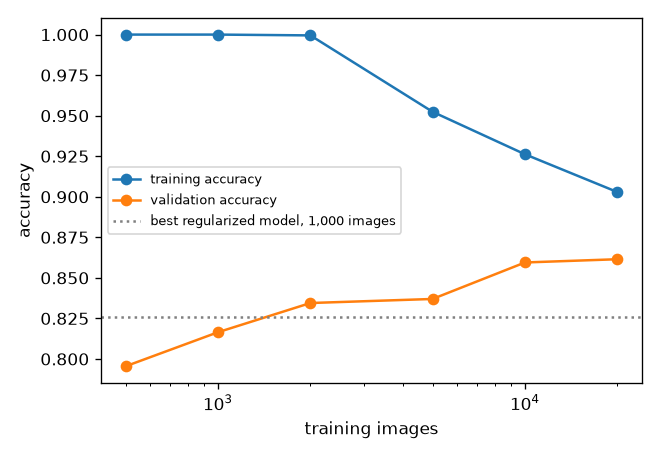

In [ ]:
from IPython.display import Image
Image('outputs/learning_curve.png')

Going from 1,000 to 2,000 images (+1.8%) beats every regularizer we tried. 10,000 images beats them all by 3%. And
look at the gap between the two curves: with 500 images the network fits its training set perfectly and validates at
0.795; with 20,000 the two curves are much closer. Over-fitting shrinks as data grows, which is exactly what
regularization tries to imitate.

The practical conclusion, worth writing in your README: **with little data, measure first.** If the learning curve is
still rising steeply, labelling more examples is likely the best use of your time. Regularization is what you reach for
when you can't.

## Step 4: write the README and publish

In [ ]:
%%writefile README.md
# Regularization with little data: what actually helps?

An ablation study in PyTorch: a 2-hidden-layer network trained on only 1,000 Fashion-MNIST images, with each
regularizer from chapter 9 switched on alone, then all together, plus model averaging, a convolutional network, and a
learning curve showing what more data would give.

![learning curve](outputs/learning_curve.png)

## Results

| setup (1,000 training images) | validation accuracy |
|---|---|
| no regularization | 0.821 (3 other seeds: 0.814 to 0.818) |
| weight decay 0.1 | 0.821 |
| dropout 0.5 | 0.813 |
| early stopping | 0.823 |
| data augmentation (2-pixel shifts) | 0.785 |
| all of the above | 0.803 |
| small CNN | 0.824 |
| average of 5 dropout networks | **0.826** |

Test set (used once): no regularization 0.808, ensemble 0.817, small CNN 0.823.
For comparison, the same network trained on 2,000 images reaches 0.835 validation accuracy, and on 10,000, 0.859.

## Run it

```bash
pip install -r requirements.txt
python study.py            # about 3 minutes
python learning_curve.py   # about 1 minute
```

## What I learned

- Regularizers are not free improvements: on this problem none of them gained more than about 1%, which is close to
  the seed-to-seed noise.
- An augmentation must match the real data: Fashion-MNIST images are centred, so random shifts made the task harder.
- More data beat every trick. Measuring that with a learning curve tells you where to spend effort.

Based on chapter 9 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Ablation study of regularization with 1,000 training images"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/small-data-regularization.git
git push -u origin main
```

## Make it yours

- **Error bars everywhere.** Run every row of the study with 3 seeds and report mean ± standard deviation. Which
  conclusions survive?
- **Better augmentation.** Try augmentations that respect the data: small changes in brightness and contrast, or tiny
  rotations of 5 degrees. Do any of them help?
- **Regularize the CNN.** The CNN was trained with no regularization. Add early stopping and averaging. Is the
  combination better than either?
- **Another data set.** Repeat the study on 1,000 MNIST digits (use your numpy-net `data.py`). Do shifts help there?
  (MNIST digits are much less carefully aligned.)

## On your CV

> **Regularization ablation study** (PyTorch): measured weight decay, dropout, early stopping, data augmentation, model
> averaging and a CNN on 1,000 training images with seed-to-seed noise; found gains of at most ~1.5%, a harmful
> augmentation, and that doubling the data beat every method. github.com/YOUR-USERNAME/small-data-regularization

## Check yourself

- [ ] You measured the noise before claiming any improvement.
- [ ] You can explain why shifting the images hurt here.
- [ ] Your README reports the results that didn't work, too.